# Level 1, Task 3: Exploratory Data Analysis (EDA)

**Codveda Technology | Data Science Internship**

**Activites Summary:**

In this notebook I explored the cleaned telecom churn data from Task 2 (`churn_cleaned.csv`, 2,512 customers). I looked at summary statistics, the shape of each variable, relationships between variables, and correlations, and I tried to find out what separates customers who leave from those who stay. I used the cleaned data in its original units (not scaled), so every number can be read directly.

## 1.0 Setting Up

### 1.1 Importing Libraries and Loading the Cleaned Data

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")             # give every chart a light grid so values are easier to read
pd.set_option("display.max_columns", None)   # show all columns when printing a table (pandas hides some by default)

df = pd.read_csv("churn_cleaned.csv")       # saved from the Task 2 notebook (Cleaning and Prerocessing) I worked on
df["area_code"] = df["area_code"].astype(str)   # needed to change it to a label

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (2367, 20)


,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,customer_service_calls,churn
0,KS,128,415,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,OH,107,415,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,NJ,137,415,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,OH,84,408,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,OK,75,415,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


**Interpretation:** The cleaned file loaded correctly with 2,512 customers and 20 columns, the same size I saved at the end of Task 2. The plan columns are now 0/1, and `churn` is 1 for customers who left.

## 2.0 Summary Statistics

### 2.1 Descriptive Statistics for the Numeric Columns

In [19]:
num = df.select_dtypes(include="number")
summary = num.agg(["mean", "median", "var", "std", "min", "max", "skew"]).T
summary.round(2)

,mean,median,var,std,min,max,skew
account_length,100.73,101.00,1504.61,38.79,1.00,205.00,-0.02
international_plan,0.10,0.00,0.09,0.30,0.00,1.00,2.68
voice_mail_plan,0.28,0.00,0.20,0.45,0.00,1.00,0.98
number_vmail_messages,8.20,0.00,189.04,13.75,0.00,50.00,1.24
total_day_minutes,179.87,179.90,2733.39,52.28,37.70,322.40,-0.01
total_day_calls,100.35,101.00,373.39,19.32,47.00,152.00,-0.03
total_day_charge,30.58,30.58,78.99,8.89,6.41,54.81,-0.01
total_eve_minutes,200.03,200.60,2447.63,49.47,61.90,337.10,0.02
total_eve_calls,100.21,100.00,385.18,19.63,48.00,154.00,0.00
total_eve_charge,17.00,17.05,17.68,4.21,5.26,28.65,0.02


**Interpretation:** For most usage columns (day, evening, night and international minutes, and the call counts) the mean and median are almost the same and the skew is close to 0. This means they are roughly symmetric, so there is no heavy tail pulling them one way. The columns that are clearly skewed to the right are `number_vmail_messages` (skew 1.25), `total_intl_calls` (1.43) and `customer_service_calls` (1.11), where most customers have low values and a few have much higher ones. The average customer makes about 180 day minutes, 201 evening minutes, 201 night minutes and 10 international minutes, and calls customer service about 1.6 times. The binary columns (plans and churn) appear here too, and their 'mean' is simply the share of customers with a 1. So about 10% have an international plan, 28% have voice mail, and 14% churned.

## 3.0 The Target Variable

### 3.1 How Many Customers Churn?

churn
0    2028
1     339
Name: count, dtype: int64
Churn rate: 14.3%


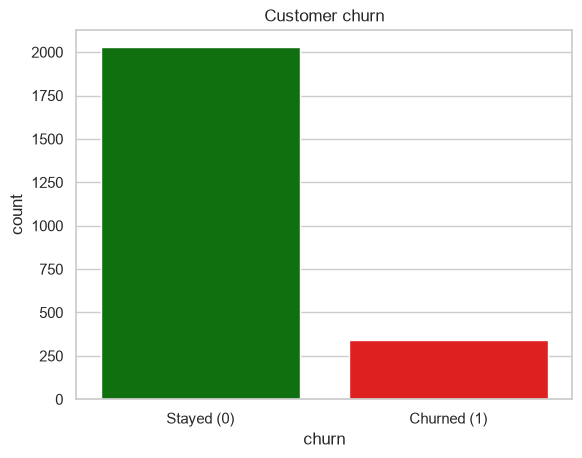

In [20]:
counts = df["churn"].value_counts().sort_index()
print(counts)
print(f"Churn rate: {df['churn'].mean():.1%}")

ax = sns.countplot(x="churn", data=df, hue="churn", palette=["green", "red"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
ax.set_title("Customer churn")
plt.show()

**Interpretation:** 2,152 customers stayed and 360 churned, so the churn rate is 14.3%. The classes are imbalanced: roughly 6 customers stay for every 1 that leaves.

## 4.0 Distribution of the Variables

### 4.1 Histograms of the Main Numeric Features

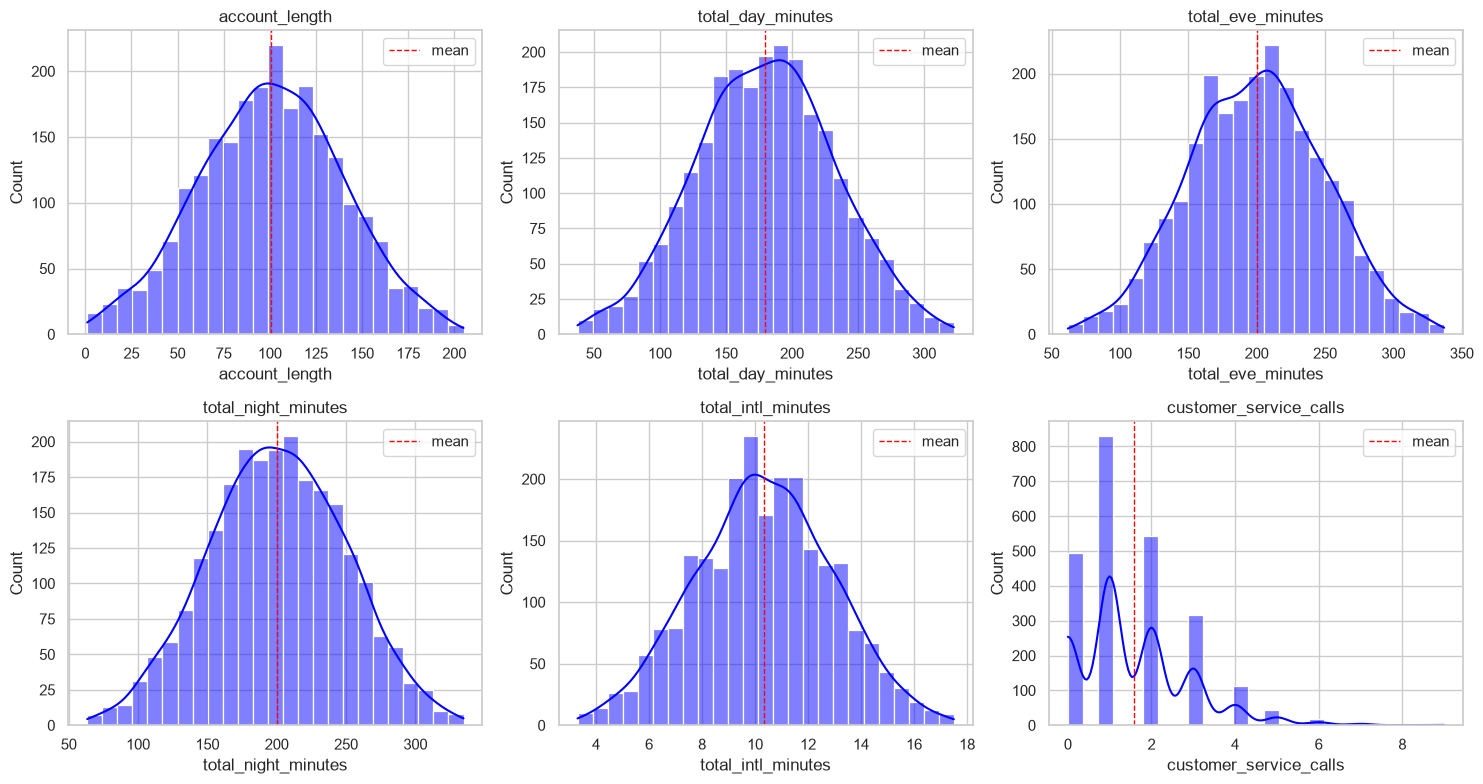

In [21]:
hist_cols = ["account_length", "total_day_minutes", "total_eve_minutes",
             "total_night_minutes", "total_intl_minutes", "customer_service_calls"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), hist_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="blue", bins=25)
    ax.axvline(df[col].mean(), color="red", ls="--", lw=1, label="mean")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Account length, day minutes, evening minutes, night minutes and international minutes all form a bell shape centred on the red mean line, which agrees with the skew values near 0. That is good news for standard models. `customer_service_calls` looks very different. It is a set of separate bars, because it is a count, and it is bunched at 0 to 2 calls with a thin tail out to 9. Most customers rarely call support, so the few who call many times stand out.

## 5.0 Relationships Between Variables

### 5.1 Scatter Plots

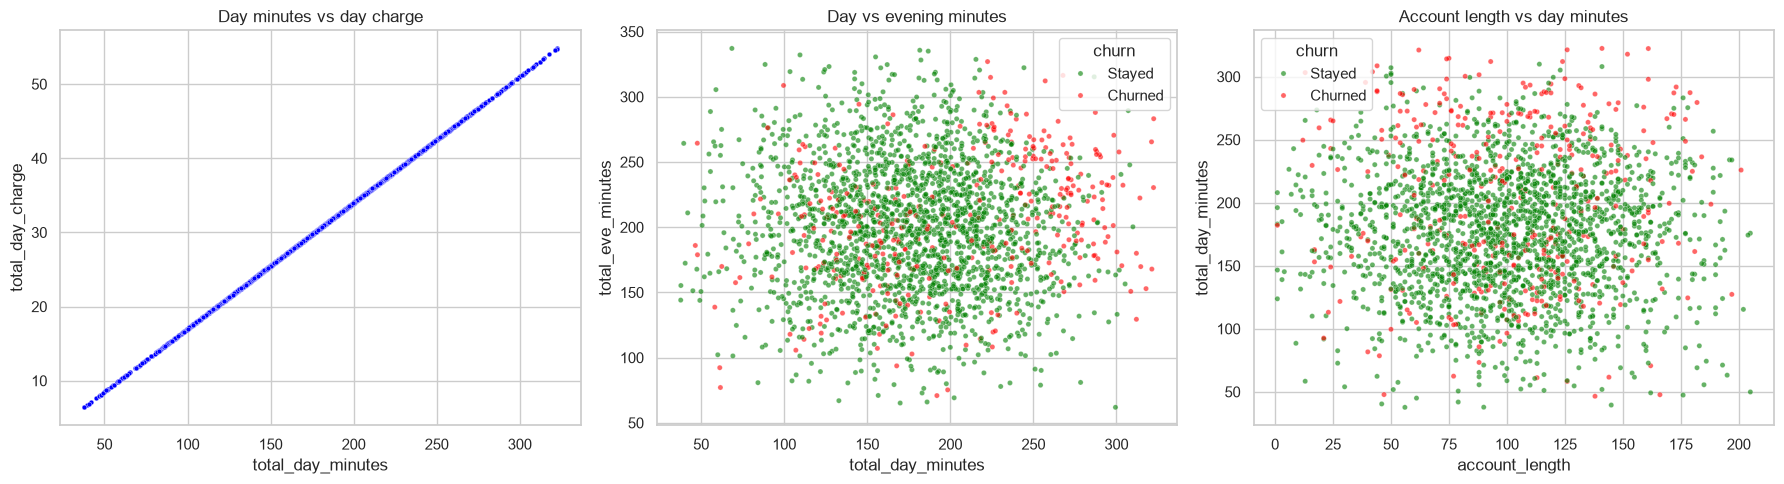

In [22]:
label = df["churn"].map({0: "Stayed", 1: "Churned"})
colours = {"Stayed": "green", "Churned": "red"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x="total_day_minutes", y="total_day_charge", data=df, ax=axes[0], s=12, color="blue")
axes[0].set_title("Day minutes vs day charge")

sns.scatterplot(x="total_day_minutes", y="total_eve_minutes", hue=label, data=df,
                ax=axes[1], s=14, alpha=0.6, palette=colours)
axes[1].set_title("Day vs evening minutes")

sns.scatterplot(x="account_length", y="total_day_minutes", hue=label, data=df,
                ax=axes[2], s=14, alpha=0.6, palette=colours)
axes[2].set_title("Account length vs day minutes")

plt.tight_layout()
plt.show()

**Interpretation:** The first plot is a perfectly straight line: day charge is just day minutes times a fixed rate, so the two columns carry the same information. In the second plot most dots are green (stayed) and spread everywhere, but the red dots (churned) gather on the right side where day minutes are above about 220. The third plot shows no clear pattern for account length. Red and green dots are mixed across all account lengths, so how long someone has been a customer does not seem to explain churn. Again the red dots sit mostly in the upper half, which is where day minutes are high.

### 5.2 Box Plots: Churned vs Retained Customers

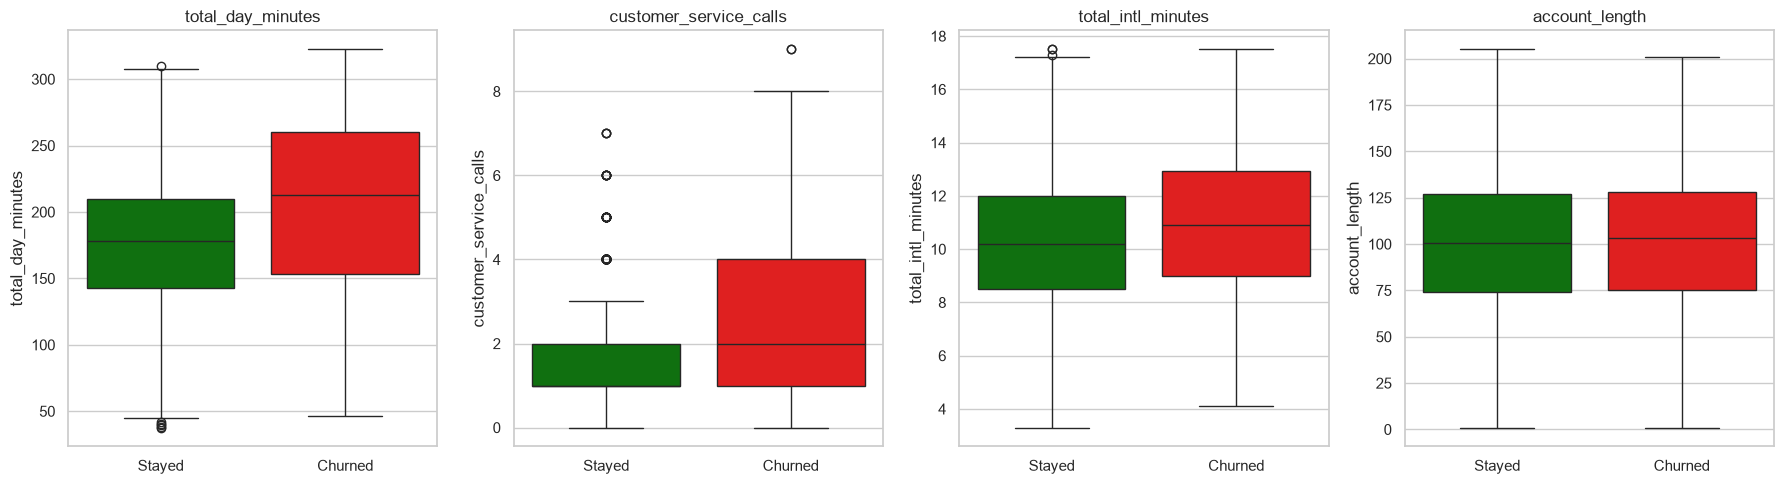

       total_day_minutes  customer_service_calls  total_intl_minutes  \
churn                                                                  
0                 178.05                     1.0                10.2   
1                 212.80                     2.0                10.9   

       account_length  
churn                  
0               100.5  
1               103.0  


In [23]:
box_cols = ["total_day_minutes", "customer_service_calls", "total_intl_minutes", "account_length"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, box_cols):
    sns.boxplot(x=label, y=df[col], ax=ax, hue=label, legend=False, palette=colours)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

print(df.groupby("churn")[box_cols].median())

**Interpretation:** Churned customers sit higher on day minutes (median 212.9 against 178.1 for those who stayed) and their box is also much taller, so there are many heavy day users among them. For customer service calls the median is 2 for churned customers and 1 for retained ones, and the churned box reaches up to 4 calls, while most retained customers stay at 3 or fewer. International minutes are slightly higher for churned customers (10.9 against 10.2). Account length is almost the same for both groups (103 against 100), which confirms what I saw in the scatter plot.

### 5.3 Churn Rate by Plan Type and Customer Service Calls

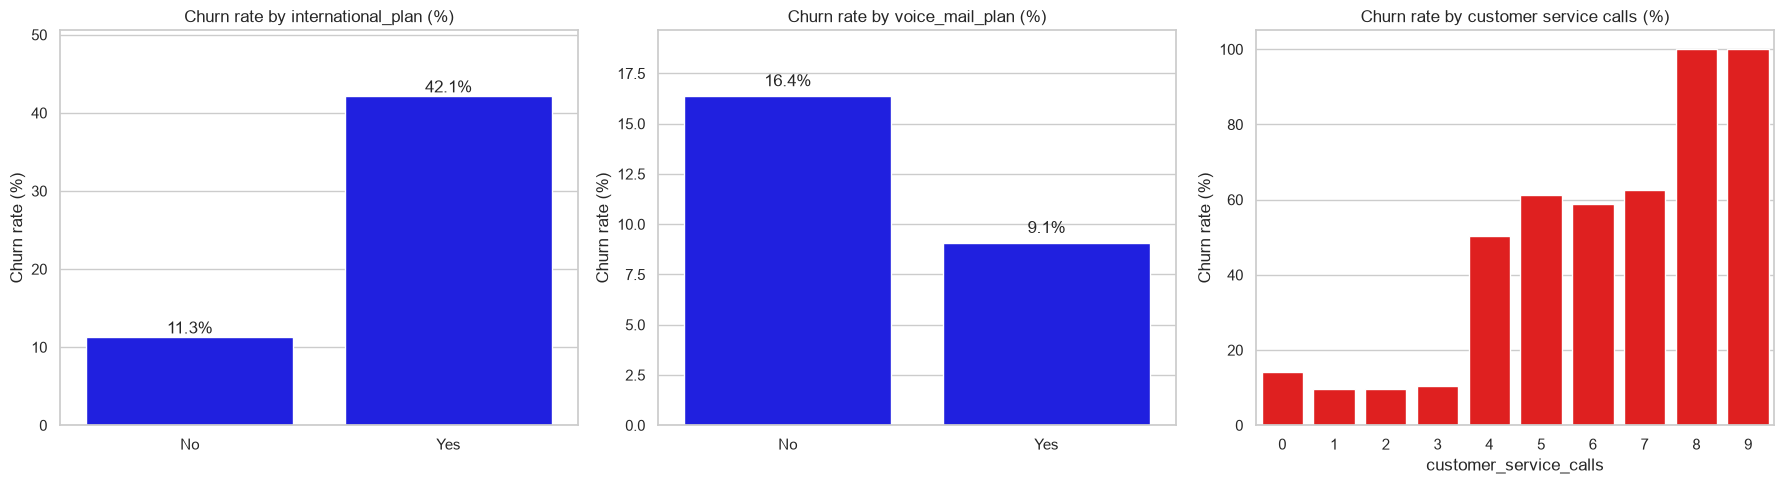

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes[:2], ["international_plan", "voice_mail_plan"]):
    rate = df.groupby(col)["churn"].mean() * 100
    sns.barplot(x=["No", "Yes"], y=rate.values, ax=ax, color="blue")
    ax.set_title(f"Churn rate by {col} (%)")
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, rate.max() * 1.2)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")

rate_calls = df.groupby("customer_service_calls")["churn"].mean() * 100
sns.barplot(x=rate_calls.index, y=rate_calls.values, ax=axes[2], color="red")
axes[2].set_title("Churn rate by customer service calls (%)")
axes[2].set_ylabel("Churn rate (%)")

plt.tight_layout()
plt.show()

**Interpretation:** The international plan makes the biggest difference. 42.1% of customers with the plan churned, against 11.2% without it. Customers with a voice mail plan are more loyal, with 9.2% churn against 16.3% without it. For customer service calls, the churn rate stays around 10% for 1 to 3 calls and then jumps sharply from the fourth call. At 8 and 9 calls the rate shows 100%, but that is only 3 customers in total, so I do not read much into those last two bars.

### 5.4 Customer Service Calls in More Detail

In [25]:
calls = df.groupby("customer_service_calls")["churn"].agg(customers="count", churn_rate="mean")
calls["churn_rate"] = (calls["churn_rate"] * 100).round(1)
print(calls)

heavy = df["customer_service_calls"] >= 4
print(f"\nCustomers with 4+ calls: {heavy.sum()} ({heavy.mean():.1%} of all customers)")
print(f"Churn rate with 4+ calls: {df[heavy]['churn'].mean():.1%}")
print(f"Churn rate with 3 or fewer calls: {df[~heavy]['churn'].mean():.1%}")

                        customers  churn_rate
customer_service_calls                       
0                             493        14.2
1                             830         9.8
2                             543         9.8
3                             316        10.4
4                             113        50.4
5                              44        61.4
6                              17        58.8
7                               8        62.5
8                               1       100.0
9                               2       100.0

Customers with 4+ calls: 185 (7.8% of all customers)
Churn rate with 4+ calls: 55.1%
Churn rate with 3 or fewer calls: 10.9%


**Interpretation:** From 0 to 3 calls the churn rate is between 9.9% and 13.9%. At 4 calls it jumps to 48.4%, and at 5 calls it reaches 60.9%. Customers with 4 or more calls are only 200 people (8.0% of the base), but 53.5% of them churn, against 10.9% for everyone else. So the fourth call looks like a clear warning point.

### 5.5 Churn by Daytime Usage and by State

In [26]:
cutoff = df["total_day_minutes"].quantile(0.75)
high = df["total_day_minutes"] > cutoff
print(f"Top 25% of day usage starts at {cutoff:.0f} minutes")
print(f"Churn rate, high day usage: {df[high]['churn'].mean():.1%}")
print(f"Churn rate, everyone else : {df[~high]['churn'].mean():.1%}")

states = df.groupby("state")["churn"].agg(customers="count", churn_rate="mean")
states["churn_rate"] = (states["churn_rate"] * 100).round(1)
print("\nHighest churn by state:")
print(states.sort_values("churn_rate", ascending=False).head(5))
print("\nChurn rate by area code (%):")
print((df.groupby("area_code")["churn"].mean() * 100).round(1))

Top 25% of day usage starts at 216 minutes
Churn rate, high day usage: 28.3%
Churn rate, everyone else : 9.7%

Highest churn by state:
       customers  churn_rate
state                       
TX            49        30.6
NJ            48        29.2
MD            53        26.4
SC            40        25.0
CA            20        25.0

Churn rate by area code (%):
area_code
408    13.8
415    14.5
510    14.4
Name: churn, dtype: float64


**Interpretation:** Customers in the top 25% of day usage (above about 216 minutes) churn at 28.3%, nearly three times the 9.7% of other customers. This could mean heavy users are unhappy with what they pay, although the data does not tell me the reason. For state, TX (30.2%) and NJ (28.6%) are highest, but each state has only about 50 customers or fewer, so differences between states could easily be random. I would not draw conclusions from them. Area code makes no difference (14.0%, 14.7% and 14.0%).

## 6.0 Correlation Analysis

### 6.1 Correlation Heatmap

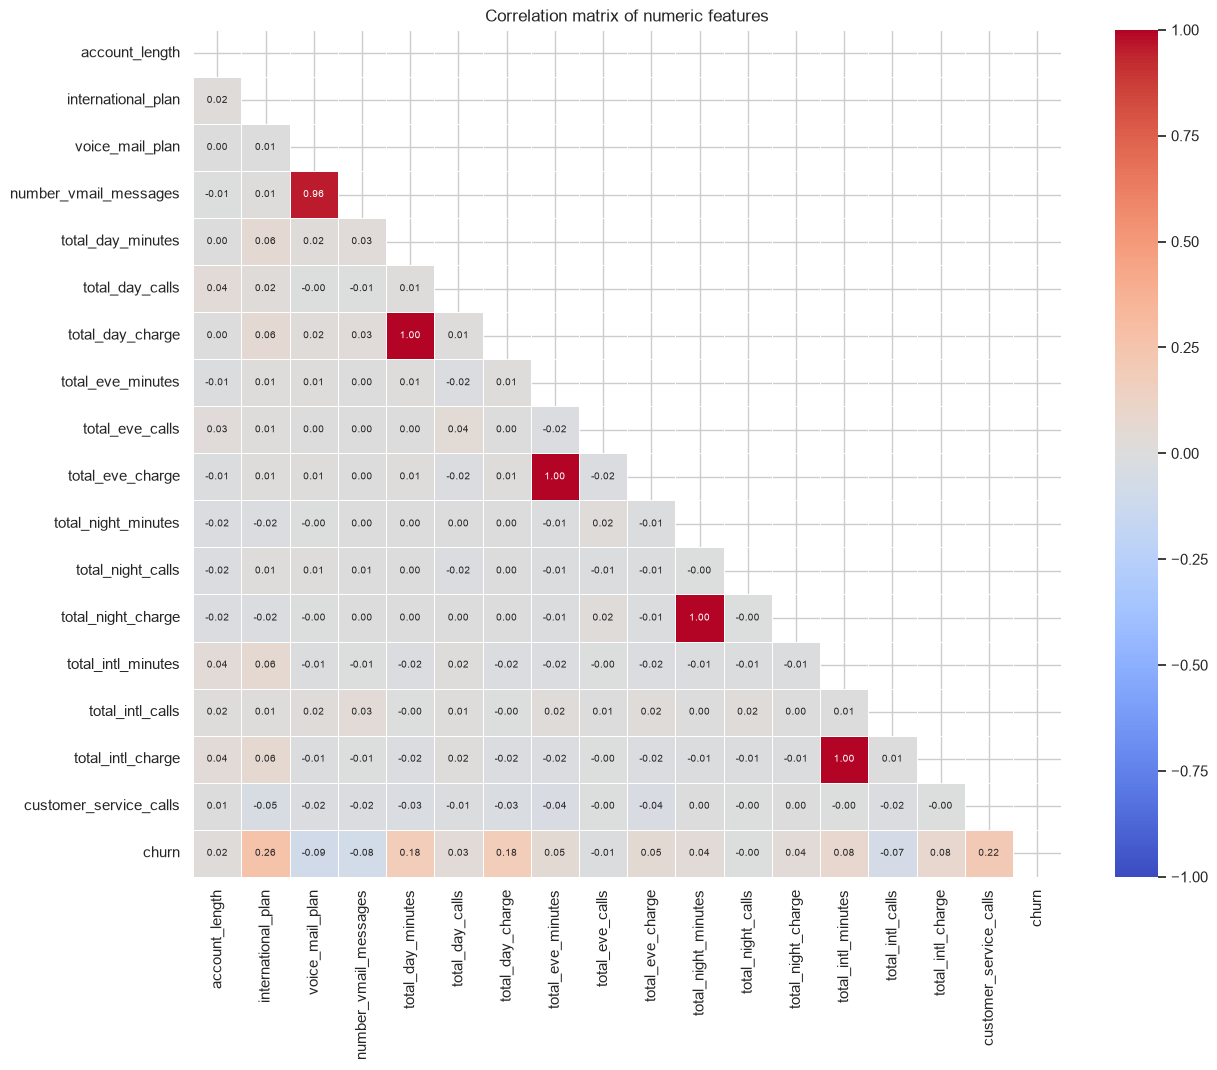

In [27]:
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))    # hide the repeated upper half

plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5)
plt.title("Correlation matrix of numeric features")
plt.show()

**Interpretation:** Most squares are close to 0, which means most pairs of features are unrelated. There are two things I notice. The minutes and charge columns for each time of day (day, evening, night, international) have a correlation of 1.00 with each other, as expected, because charge is calculated from minutes. Also `voice_mail_plan` and `number_vmail_messages` are very strongly related (0.96), since anyone with the plan has messages. In the churn row, the strongest colours are for `international_plan`, `customer_service_calls` and `total_day_minutes`.

### 6.2 Correlation with Churn and Redundant Features

In [28]:
churn_corr = corr["churn"].drop("churn").sort_values(key=abs, ascending=False)
print("Strongest correlations with churn:")
print(churn_corr.round(3).head(8))

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("\nFeature pairs with correlation above 0.8:")
print(pairs[pairs.abs() > 0.8].sort_values(ascending=False).round(3))

Strongest correlations with churn:
international_plan        0.264
customer_service_calls    0.216
total_day_minutes         0.185
total_day_charge          0.185
voice_mail_plan          -0.094
total_intl_charge         0.081
total_intl_minutes        0.081
number_vmail_messages    -0.080
Name: churn, dtype: float64

Feature pairs with correlation above 0.8:
total_day_minutes    total_day_charge         1.000
total_eve_minutes    total_eve_charge         1.000
total_night_minutes  total_night_charge       1.000
total_intl_minutes   total_intl_charge        1.000
voice_mail_plan      number_vmail_messages    0.957
dtype: float64


**Interpretation:** The strongest correlations with churn are `international_plan` (0.26), `customer_service_calls` (0.21) and `total_day_minutes` (0.18). These are modest values, so no single feature explains churn on its own. Voice mail plan has a small negative link (-0.09), meaning those customers churn a little less. The five pairs above 0.8 are redundant: each minutes/charge pair, and the voice mail plan with its message count. When I build the logistic regression model I should keep only one column from each pair, to avoid multicollinearity.

## 7.0 Insights and Recommendations

### 7.1 Key Findings
All figures come from the cleaned data (2,512 customers, overall churn rate 14.3%).

1. **Customer service calls are the strongest warning sign.** Churn stays near 10% for 1 to 3 calls but rises to 48.4% at 4 calls and about 60% at 5 or more. The 200 customers with 4+ calls churn at 53.5%, against 10.9% for everyone else.
2. **The international plan is linked to high churn.** 42.1% of customers with the plan left, against 11.2% without it. It also has the highest correlation with churn (0.26). Only about 10% of customers have this plan, so it is a small but high-risk group.
3. **Heavy daytime users leave more often.** The top 25% of day usage (above about 216 minutes) churn at 28.3%, against 9.7% for the rest.
4. **Voice mail customers are more loyal.** Churn is 9.2% with the plan and 16.3% without it.
5. **Some features do not help much.** Account length (correlation 0.02), area code and evening or night usage show little or no link to churn.
6. **State results are unreliable.** TX and NJ look high, but each state has few customers, so I would not treat this as a finding.

### 7.2 Data Quality Notes
- The usage columns are close to bell-shaped, which suits standard models.
- Only 14.3% of customers churn, so accuracy alone will be misleading in Level 2.
- Each charge column duplicates its minutes column (correlation 1.00), and `voice_mail_plan` almost duplicates `number_vmail_messages` (0.96). I will keep one from each pair when modelling.

### 7.3 Recommendations
- Flag customers who make a third customer service call and contact them before a fourth.
- Review the pricing and service quality of the international plan.
- Offer high-usage customers a better day-time plan before they leave.
- Consider promoting voice mail, which is linked to lower churn (this is a link, not proof that it causes customers to stay).

### 7.4 Limitations
These findings show relationships, not causes. I removed 154 outliers (5.8%) in Task 2, and the data comes from one telecom company, so the results may not apply elsewhere.